# Active Subspace Analysis for NACA0012 Airfoil Design

__Trent Lukaczyk__, Stanford University

__Paul Constantine__, Colorado School of Mines

__Ryan Howard__, Colorado School of Mines

<br>

In this notebook, we summarize the _active subspaces_ method and apply it to the lift and drag of the NACA0012 airfoil, the example of section 5.3.1 of [[1]][R1]. We use all the distinct samples in the data set; the book's Fig. 5.11 uses only the first 122, and we reproduce that figure at the end. The notebook uses the [active_subspaces](https://github.com/paulcon/active_subspaces) library, version 1.0 or later. It runs in Python 3 with numpy and matplotlib (see the repository's `requirements.txt`) and takes a few seconds.

### Introduction

Engineering and physical models usually contain several parameters whose values can greatly affect the output of the model. It is often of interest how model output changes with changes to parameters, but the number of model evaluations required to characterize this dependence grows exponentially with the dimension of the parameter space; if the model is expensive, it may be practically impossible to obtain enough runs for an exhaustive study. One approach to solving this problem is dimension reduction: reducing the dimension of the parameter space to make traditional methods feasible. _Active subspaces_ is one method of dimension reduction that looks for linear combinations of input parameters whose values are more important to characterizing output than values of orthogonal linear combinations. Here, we'll present the method and apply it to the NACA0012 airfoil.

### Active Subspaces

Consider a model's scalar-valued output, $f$, as a function of $m$ normalized inputs, $\mathbf x:\ f = f(\mathbf x)$. The active subspace method is based on the matrix

$$
\mathbf C = \int\nabla f(\mathbf x)\nabla f(\mathbf x)^T\rho(\mathbf x)\ d\mathbf x = \mathbf W\Lambda\mathbf W^T,
$$

where $\rho$ is a probability density on $\mathbf x$ and $\mathbf W\Lambda\mathbf W^T$ is the eigendecomposition of $\mathbf C$ with the eigenvalues in descending order. The eigenpairs satisfy the relationship $\lambda_i = \int(\nabla f^T\mathbf w_i)^2\rho\ d\mathbf x$; this means the eigenvalues quantify the change of $f$ in the directions defined by the corresponding eigenvectors. If the first $n<m$ eigenvalues are much larger than the rest, we can partition the decomposition as

$$
\Lambda = \left[\begin{matrix}\Lambda_1 & \\ & \Lambda_2\end{matrix}\right],\ \mathbf W = \left[\begin{matrix}\mathbf W_1 & \mathbf W_2\end{matrix}\right],
$$

where $\Lambda_1$ contains the first $n$ eigenvalues and $\mathbf W_1$ the corresponding eigenvectors. Since the values in $\Lambda_1$ are much larger than those in $\Lambda_2$, $f$ will likely be relatively flat in the directions defined by the span of $\mathbf W_2$ and we can approximate $f(\mathbf x)\approx g(\mathbf W_1^T\mathbf x) = g(\mathbf y)$ for some $g:R^n\rightarrow R$, where $\mathbf y\equiv \mathbf W_1^T\mathbf x\in R^n$ are called the _active variables_; this reduces the input dimension from $m$ to $n<m$.

Since $\mathbf C$ usually can't be computed analytically, it must be numerically approximated. One method of approximation is simple Monte Carlo: draw $\{\mathbf x_j\}_{j=1}^M$ from $\rho$, compute $\nabla f_j = \nabla f(\mathbf x_j)\ \forall j$, and then $\mathbf C \approx \frac 1 M\sum_{j=1}^M\nabla f_j\nabla f_j^T$.

### The NACA0012 Airfoil

The NACA0012 airfoil is a standard test problem for transonic, compressible flow in two spatial dimensions. The shape of the airfoil is parameterized by 18 Hicks-Henne bump functions, and the parameters are the heights of the bumps; changes in the parameters smoothly deform the geometry. Each parameter varies uniformly in $[-0.01, 0.01]$, and 0 is the baseline NACA0012. For the active subspace analysis, we normalize this parameter space to the hypercube $[-1, 1]^{18}$ and choose $\rho$ to be uniform on this space. Given values of the parameters, the [SU2](https://su2code.github.io/) compressible flow solver computes our two quantities of interest (model outputs), the lift and drag coefficients, and the SU2 adjoint solver computes their gradients with respect to the parameters. Each output has its own active subspace.

The data are stored SU2 output: the runs cannot be repeated from this repository. The flow conditions (Mach number, angle of attack, Euler or RANS), the SU2 version, and which bump (upper or lower surface, chord station) each parameter moves are not recorded with the data or in [[1]][R1]; see `DATA.md`.

### References

[[1]][R1] P.G. Constantine. _Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies_. SIAM, 2015. doi:10.1137/1.9781611973860

[[2]][R2] T.W. Lukaczyk, F. Palacios, J.J. Alonso, and P.G. Constantine. _Active Subspaces for Shape Optimization_. 10th AIAA Multidisciplinary Design Optimization Conference, AIAA SciTech, National Harbor, MD, January 2014. AIAA 2014-1171. doi:10.2514/6.2014-1171

[R1]: https://doi.org/10.1137/1.9781611973860
[R2]: https://doi.org/10.2514/6.2014-1171

### Acknowledgments

This material is based upon work supported by the U.S. Department of Energy Office of Science, Office of Advanced Scientific Computing Research, Applied Mathematics program under Award Number DE-SC-0011077.

<br>

We'll now code up the analysis using the [active_subspaces](https://github.com/paulcon/active_subspaces) library.

In [1]:
%matplotlib inline
import time

import numpy as np
import matplotlib.pyplot as plt
import active_subspaces as ac

t_start = time.perf_counter()
rng = np.random.default_rng(2015)        # the only source of randomness (the bootstrap) in this notebook

Import the data set. Distinguish inputs, outputs, and gradients. The file `NACA0012.txt` has a header line and one row per SU2 run: the run number, the 18 parameters `x01`–`x18`, the lift and drag coefficients, and their gradients `dlift01`–`dlift18` and `ddrag01`–`ddrag18`. The inputs are in physical units ($[-0.01, 0.01]$), and so are the gradients: they are derivatives with respect to the physical parameters, not the normalized ones.

In [2]:
with open('NACA0012.txt') as fh:
    header = fh.readline().strip().split(',')
data = np.loadtxt('NACA0012.txt', delimiter=',', skiprows=1)

m = 18                                   # number of input parameters
run = data[:, 0].astype(int)
X_all = data[:, 1:m+1]                   # inputs, physical units
f_all = {'Lift': data[:, m+1], 'Drag': data[:, m+2]}
G_all = {'Lift': data[:, m+3:2*m+3],     # gradients with respect to the PHYSICAL inputs
         'Drag': data[:, 2*m+3:]}
names = header[1:m+1]
qois = ['Lift', 'Drag']
print(f'{data.shape[0]} runs, {m} parameters; inputs in [{X_all.min():.7f}, {X_all.max():.7f}], '
      f'std {X_all.std():.5f} (uniform on [-0.01, 0.01]: {0.01/np.sqrt(3):.5f})')

1756 runs, 18 parameters; inputs in [-0.0099995, 0.0099997], std 0.00576 (uniform on [-0.01, 0.01]: 0.00577)


Two checks on the data. First, run 945 repeats run 1, the nominal design (all parameters zero), with identical outputs and gradients; the file seems to join two batches of runs, each starting at the nominal design (where the second batch came from is not recorded). We drop every row whose 18 inputs repeat an earlier row, which removes only run 945, and keep the file as it is.

Second, the gradients are with respect to the physical inputs. If they were with respect to the normalized inputs, the slope of a least-squares linear fit of $f$ on the physical inputs would be about 100 times the mean gradient; it is about the same.

In [3]:
_, first = np.unique(X_all, axis=0, return_index=True)
keep = np.zeros(len(X_all), dtype=bool)
keep[first] = True
for i in np.flatnonzero(~keep):
    j = np.flatnonzero((X_all[:i] == X_all[i]).all(axis=1))[0]
    print(f'dropped run {run[i]}: same inputs as run {run[j]}; '
          f'outputs and gradients identical: {np.array_equal(data[i, 1:], data[j, 1:])}; '
          f'max |x| = {np.abs(X_all[i]).max()}')
X = X_all[keep]
f = {q: f_all[q][keep] for q in qois}
G = {q: G_all[q][keep] for q in qois}
M = len(X)
print(f'M = {M} samples kept')

A = np.hstack([np.ones((M, 1)), X])
for q in qois:
    slope = np.linalg.lstsq(A, f[q], rcond=None)[0][1:]
    g_mean = G[q].mean(axis=0)
    print(f'{q}: (linear-fit slope . mean gradient) / |mean gradient|^2 = {slope @ g_mean / (g_mean @ g_mean):.3f}, '
          f'correlation {np.corrcoef(slope, g_mean)[0, 1]:.4f}')

dropped run 945: same inputs as run 1; outputs and gradients identical: True; max |x| = 0.0
M = 1755 samples kept
Lift: (linear-fit slope . mean gradient) / |mean gradient|^2 = 1.013, correlation 0.9994
Drag: (linear-fit slope . mean gradient) / |mean gradient|^2 = 1.014, correlation 0.9992


Compute the active subspaces. The input space is the box $[-0.01, 0.01]^{18}$ with the uniform density; `ac.active_subspace` takes the physical gradients and maps them to the normalized coordinates by the chain rule, multiplying each by the half-width 0.01.

The 2016 version of this notebook passed the physical gradients as if they were normalized ones. Its eigenvectors are the same (all 18 parameters have the same range), but its eigenvalues are $1/0.01^2 = 10^4$ times ours. We first check this on all 1756 rows, with the 2016 computation (the eigendecomposition of $\frac 1 M\sum_j\nabla f_j\nabla f_j^T$ for the raw gradients), and then compute the subspaces on the kept samples with 200 bootstrap replicates, as in 2016.

Eigenvector signs are arbitrary. v1 makes each eigenvector's largest component positive; we use `ac.orient` to make the first component of the first two eigenvectors positive instead, the 2016 package's rule, so that the figures match the 2016 notebook. (v1's own rule would mirror the second drag eigenvector.)

In [4]:
space = ac.Uniform(np.full(m, -0.01), np.full(m, 0.01), names=names)
e1 = np.eye(m)[:, [0, 0]]                # reference for the 2016 sign rule: first component positive
fmt = lambda v: ', '.join(f'{x:.4g}' for x in v)

print('check against the 2016 computation, all 1756 rows')
for q in qois:
    lam16, W16 = np.linalg.eigh(G_all[q].T @ G_all[q] / len(G_all[q]))
    lam16, W16 = lam16[::-1], W16[:, ::-1]
    s = ac.active_subspace(space=space, grads=G_all[q], qoi=q)
    print(f'  {q}: lambda_1..3 = {fmt(s.eigenvalues[:3])}; 2016 values x 1e-4 = {fmt(lam16[:3] * 1e-4)}; '
          f'max relative difference {np.max(np.abs(s.eigenvalues[:3] / (lam16[:3] * 1e-4) - 1)):.0e}; '
          f'|1 - |w1 . w1(2016)|| = {abs(1 - abs(s.W[:, 0] @ W16[:, 0])):.0e}')

sub = {}
for q in qois:
    sub[q] = ac.orient(ac.active_subspace(space=space, grads=G[q], nboot=200, rng=rng, qoi=q),
                       by='reference', reference=e1, columns=2)
print(f'\nthe {M} kept samples')
for q in qois:
    lam = sub[q].eigenvalues
    print(f'  {q}: lambda_1..7 = {fmt(lam[:7])}')
    print(f'  {" " * len(q)}  lambda_1/lambda_2 = {lam[0] / lam[1]:.1f}, lambda_4/lambda_5 = {lam[3] / lam[4]:.1f}, '
          f'dimension chosen by the eigenvalue-gap rule (EVG): n = {sub[q].n}')

check against the 2016 computation, all 1756 rows
  Lift: lambda_1..3 = 0.08557, 0.005377, 0.002506; 2016 values x 1e-4 = 0.08557, 0.005377, 0.002506; max relative difference 2e-15; |1 - |w1 . w1(2016)|| = 4e-16
  Drag: lambda_1..3 = 0.000618, 0.0001186, 5.945e-05; 2016 values x 1e-4 = 0.000618, 0.0001186, 5.945e-05; max relative difference 2e-15; |1 - |w1 . w1(2016)|| = 9e-16



the 1755 kept samples
  Lift: lambda_1..7 = 0.08556, 0.00538, 0.002507, 0.001527, 0.0006397, 0.0005095, 0.0004638
        lambda_1/lambda_2 = 15.9, lambda_4/lambda_5 = 2.4, dimension chosen by the eigenvalue-gap rule (EVG): n = 1
  Drag: lambda_1..7 = 0.000618, 0.0001186, 5.946e-05, 3.675e-05, 1.354e-05, 5.92e-06, 2.346e-06
        lambda_1/lambda_2 = 5.2, lambda_4/lambda_5 = 2.7, dimension chosen by the eigenvalue-gap rule (EVG): n = 1


Plot the eigenvalues and subspace errors, with the minimum-to-maximum ranges over the bootstrap replicates (the 2016 band; the v1 default is a 95% percentile band). The dotted line marks the dimension $n$ that the eigenvalue-gap rule chose.

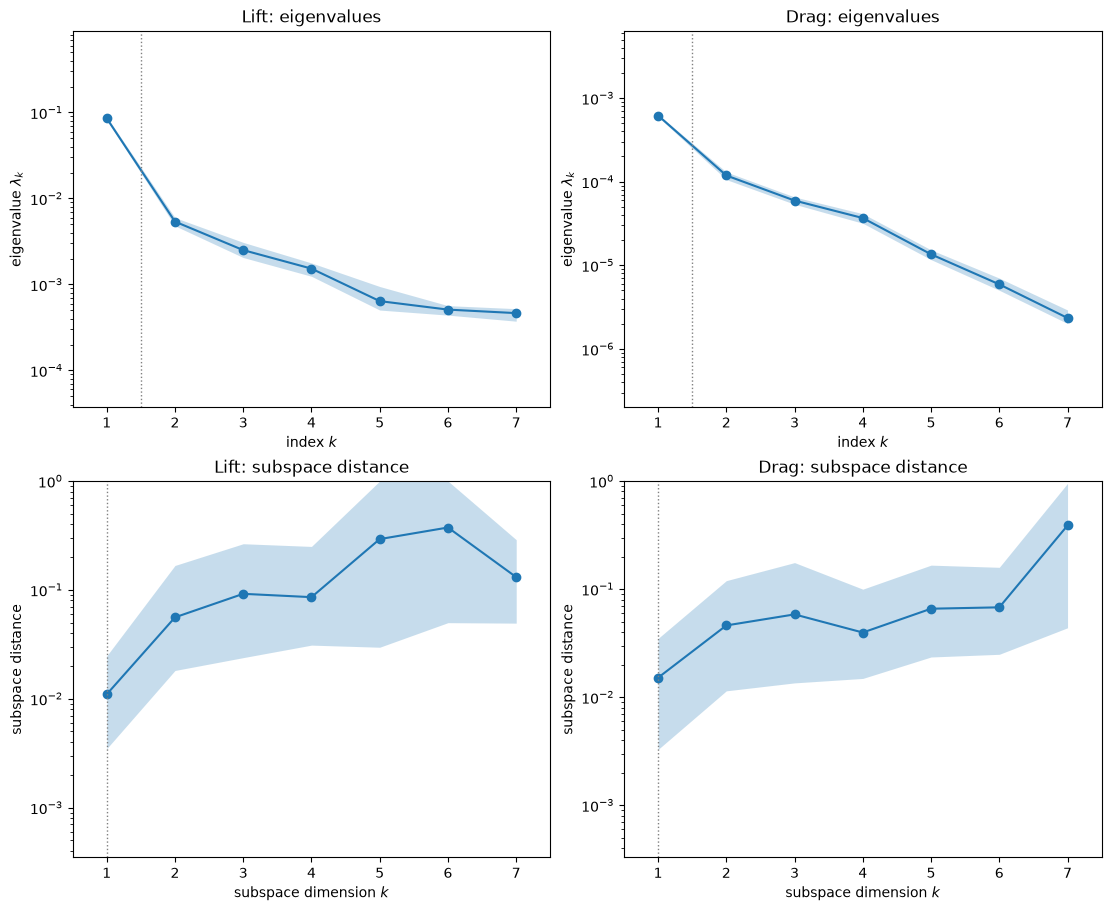

In [5]:
k = 7   # number of eigenvalues to plot
fig, axes = plt.subplots(2, 2, figsize=(11, 9), layout='constrained')
for j, q in enumerate(qois):
    ac.plotting.plot_eigenvalues(sub[q], interval='minmax', k_max=k, ax=axes[0, j])
    ac.plotting.plot_subspace_errors(sub[q], interval='minmax', k_max=k, ax=axes[1, j])
    axes[0, j].set_title(f'{q}: eigenvalues')
    axes[1, j].set_title(f'{q}: subspace distance')

In both cases, we see significant declines between the first and second eigenvalues and correspondingly low subspace error associated with the 1-dimensional subspace. However, the eigenvalue gap is smaller for drag ($\lambda_1/\lambda_2 \approx 5.2$) than for lift ($\approx 15.9$); we might therefore expect a comparatively inaccurate 1-dimensional subspace for drag.

To assess subspace quality, we now construct 1- and 2-dimensional sufficient summary plots, which show output (lift and drag) against the first 1 or 2 active variables ($\mathbf w_1^T\mathbf x$ and $\mathbf w_2^T\mathbf x$, with $\mathbf x$ the normalized inputs); tight trends in these plots indicate good subspace quality.

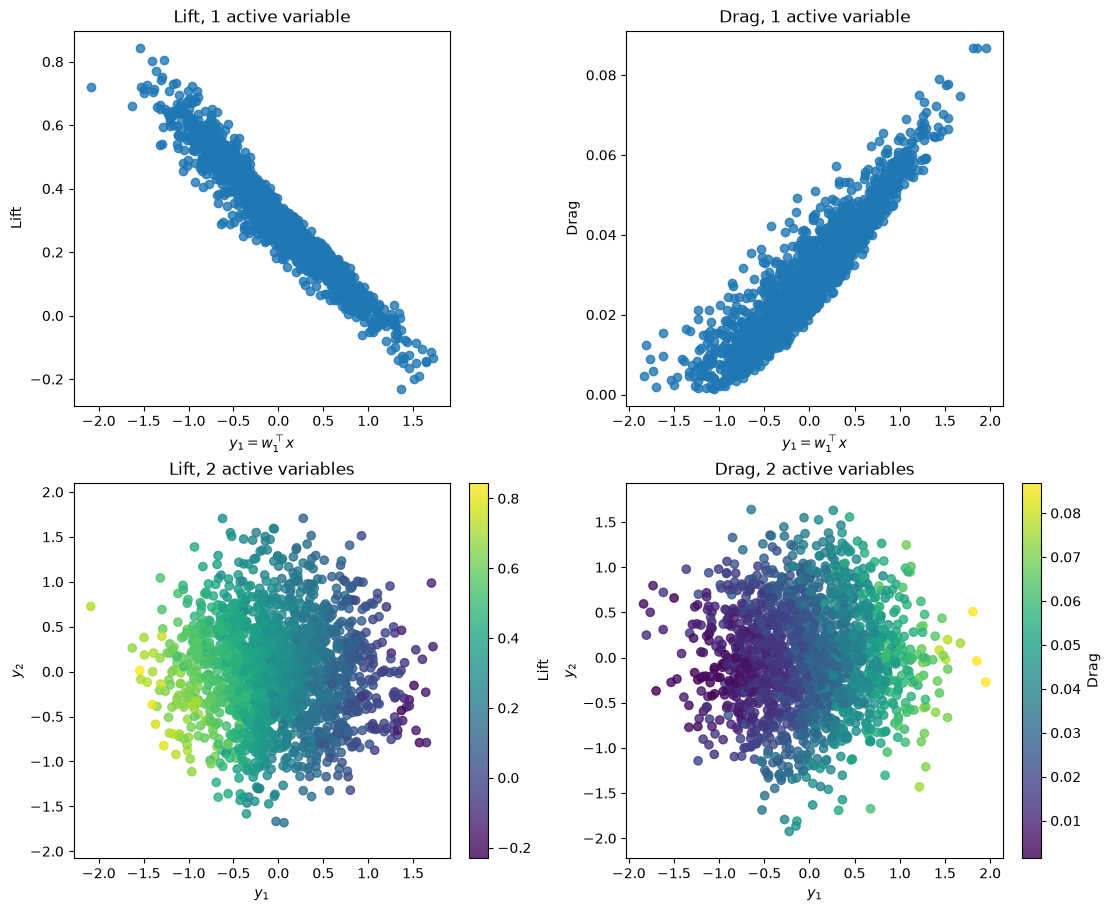

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(11, 9), layout='constrained')
for j, q in enumerate(qois):
    for i, dims in enumerate((1, 2)):
        ac.plotting.plot_sufficient_summary(sub[q], X=X, f=f[q], dims=dims, ax=axes[i, j])
        axes[i, j].set_title(f'{q}, {dims} active variable{"s" if dims == 2 else ""}')

We see significant univariate trends in the 1-dimensional plots, though more deviation from this trend is seen for drag than for lift, as the eigenvalues would lead us to expect. To put numbers on this, we fit a quadratic polynomial in the first one or two active variables and compute its leave-one-out $R^2$.

In [7]:
for q in qois:
    r2 = [ac.fit_surrogate(X=X, f=f[q], subspace=ac.with_dimension(sub[q], n), kind='poly', degree=2).loo_r_squared
          for n in (1, 2)]
    print(f'{q}: quadratic surrogate, leave-one-out R^2 = {r2[0]:.3f} (n = 1), {r2[1]:.3f} (n = 2)')

Lift: quadratic surrogate, leave-one-out R^2 = 0.934 (n = 1), 0.965 (n = 2)
Drag: quadratic surrogate, leave-one-out R^2 = 0.870 (n = 1), 0.928 (n = 2)


A univariate quadratic explains 93% of the variation in lift and 87% in drag; adding the second active variable raises drag to 93%. So while a 1-dimensional subspace would likely be sufficient for lift, a 2- or higher-dimensional subspace might be more appropriate for drag. This reading of the full data set differs from the book's: with the first 122 samples, [[1]][R1] (p. 83) finds the gap between the first and second drag eigenvalues close to the gap between the fourth and fifth, and calls drag "one- or four-dimensional" (reproduced at the end of this notebook).

The eigenvector components provide a measure of sensitivity; higher-magnitude components indicate relative sensitivity to the corresponding parameter. To illustrate the NACA0012 model's sensitivity, we plot the components of the first 2 eigenvectors for lift and drag.

Lift: sum |w1| over x01-x09 = 1.86, over x10-x18 = 1.94; w1 = [ 0.08  0.11  0.13  0.16  0.19  0.23  0.27  0.31  0.38 -0.13 -0.11 -0.08
 -0.1  -0.17 -0.28 -0.37 -0.37 -0.33]
Drag: sum |w1| over x01-x09 = 1.02, over x10-x18 = 2.15; w1 = [ 0.07  0.13  0.12  0.05 -0.05 -0.12 -0.15 -0.15 -0.18  0.4   0.58  0.5
  0.29  0.06 -0.07 -0.06  0.05  0.14]


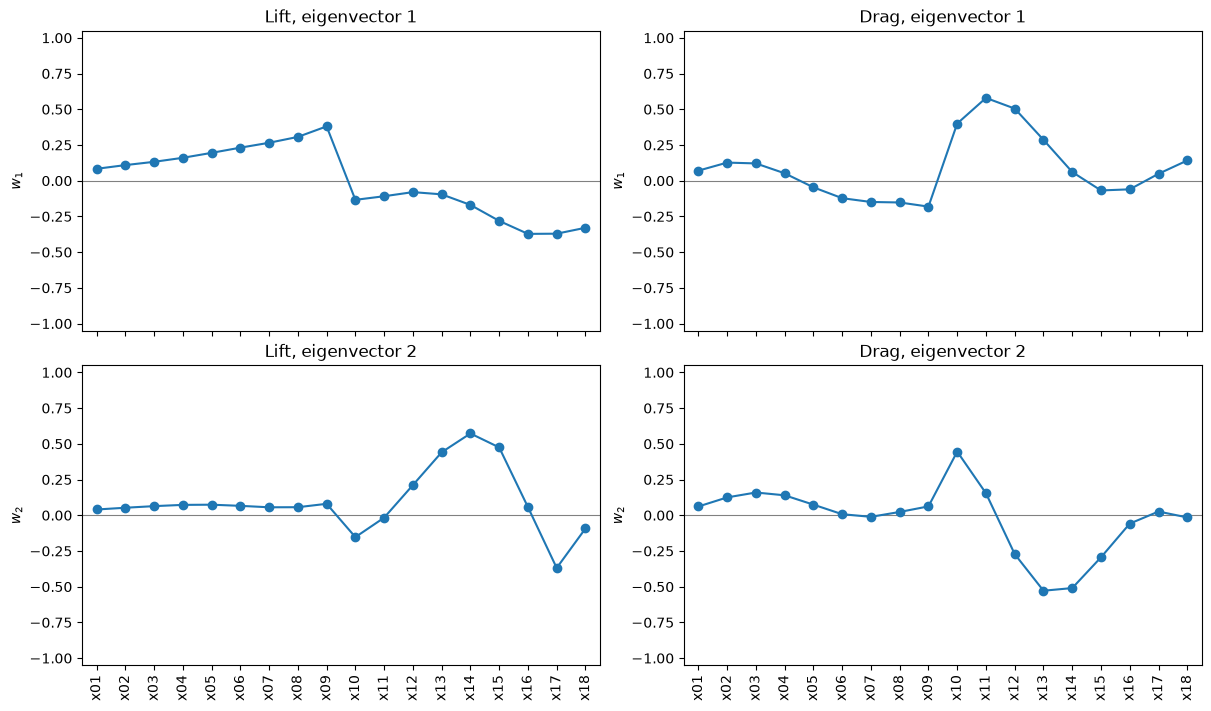

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True, layout='constrained')
for j, q in enumerate(qois):
    ac.plotting.plot_eigenvectors(sub[q], indices=[0, 1], ax=axes[:, j])
    for i in range(2):
        axes[i, j].set_title(f'{q}, eigenvector {i + 1}')
        axes[i, j].tick_params(axis='x', labelrotation=90)
for q in qois:
    w1 = sub[q].W[:, 0]
    print(f'{q}: sum |w1| over x01-x09 = {np.abs(w1[:9]).sum():.2f}, over x10-x18 = {np.abs(w1[9:]).sum():.2f}; '
          f'w1 = {np.array2string(w1, precision=2)}')

For drag, the last nine parameters carry most of the weight in the first eigenvector, twice as much as the first nine. For lift, the weight is spread over both halves, with opposite signs: the first nine components are positive and the last nine negative. Which parts of the airfoil the two halves move (for example, the upper and lower surfaces) is not recorded, so we do not interpret the halves further.

The active subspaces we've constructed can be used for several applications, such as (constrained) optimization, integration, and surrogate modeling. [[2]][R2] discusses some of these applications in detail for the design of the ONERA-M6 wing, a problem similar to what we've discussed here; see this repository's [ONERA_M6_Wing](../ONERA_M6_Wing/ONERA_M6_Wing.ipynb) notebook.

### The book's figures

[[1]][R1] §5.3.1 uses Algorithm 3.3 with $k = 7$ eigenvalues and multiplier $\alpha = 6$, so $M = \lceil\alpha k\log m\rceil = 122$ gradient samples, and 1000 bootstrap replicates. The book does not say which samples; the eigenvalues of the first 122 rows of the file match its Fig. 5.11, so we use those. The book's eigenvalues are in the 2016 units, $10^4$ times ours, so we print ours multiplied by $10^4$ beside the values read off the book's figure. The subspace distances do not depend on the units. Bootstrap ranges are random, so only their general size can be compared.

M = ceil(6 * 7 * log(18)) = 122



Drag, first 122 rows        1        2        3        4        5        6        7
        eigenvalues x 1e4     6.47     1.45    0.583    0.416    0.106   0.0451   0.0168
                     book        6      1.4     0.55      0.4      0.1    0.045    0.017
   mean subspace distance    0.055    0.175    0.297    0.119    0.179    0.211    0.628
                     book    0.055    0.180    0.300    0.110    0.170    0.200    0.600
                         lambda_1/lambda_2 = 4.5, lambda_4/lambda_5 = 3.9

Lift, first 122 rows        1        2        3        4        5        6        7
        eigenvalues x 1e4      877     47.3     27.7     18.9     6.58     4.26     3.41
                     book      800       45       25       20        6        4      3.5
   mean subspace distance    0.041    0.279    0.417    0.216    0.468    0.596    0.684
                     book    0.040    0.250    0.400    0.220    0.450    0.550    0.600
                         lambda_1/lambda_2 = 

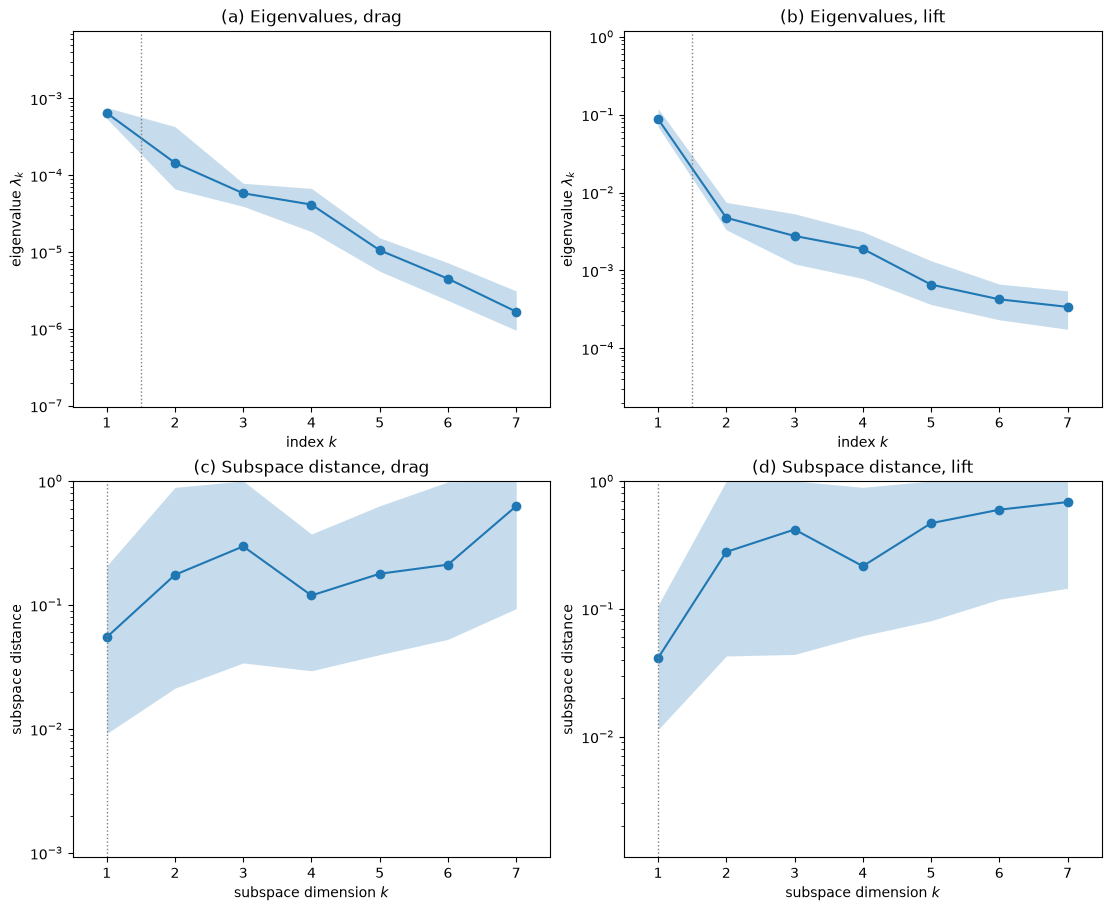

In [9]:
alpha, k = 6, 7
M_book = int(np.ceil(alpha * k * np.log(m)))
print(f'M = ceil({alpha} * {k} * log({m})) = {M_book}\n')

book = {  # read off the log-scale plots of [1] Fig. 5.11, so about 10% accuracy
    'Drag': {'eigenvalues': [6, 1.4, 0.55, 0.4, 0.1, 0.045, 0.017],
             'distance': [0.055, 0.18, 0.3, 0.11, 0.17, 0.2, 0.6]},
    'Lift': {'eigenvalues': [800, 45, 25, 20, 6, 4, 3.5],
             'distance': [0.04, 0.25, 0.4, 0.22, 0.45, 0.55, 0.6]}}
sub_book = {q: ac.active_subspace(space=space, grads=G_all[q][:M_book], nboot=1000, rng=rng, qoi=q)
            for q in ['Drag', 'Lift']}
for q in ['Drag', 'Lift']:
    s = sub_book[q]
    print(f'{q}, first {M_book} rows' + ''.join(f'{i:>9d}' for i in range(1, k + 1)))
    print(f'{"eigenvalues x 1e4":>25}' + ''.join(f'{v:9.3g}' for v in s.eigenvalues[:k] * 1e4))
    print(f'{"book":>25}' + ''.join(f'{v:9.3g}' for v in book[q]['eigenvalues']))
    print(f'{"mean subspace distance":>25}' + ''.join(f'{v:9.3f}' for v in s.bootstrap_distances.mean(axis=0)[:k]))
    print(f'{"book":>25}' + ''.join(f'{v:9.3f}' for v in book[q]['distance']))
    lam = s.eigenvalues
    print(f'{"":>25}lambda_1/lambda_2 = {lam[0] / lam[1]:.1f}, lambda_4/lambda_5 = {lam[3] / lam[4]:.1f}\n')

fig, axes = plt.subplots(2, 2, figsize=(11, 9), layout='constrained')
for j, q in enumerate(['Drag', 'Lift']):
    ac.plotting.plot_eigenvalues(sub_book[q], interval='minmax', k_max=k, ax=axes[0, j])
    ac.plotting.plot_subspace_errors(sub_book[q], interval='minmax', k_max=k, ax=axes[1, j])
    axes[0, j].set_title(f'({"ab"[j]}) Eigenvalues, {q.lower()}')
    axes[1, j].set_title(f'({"cd"[j]}) Subspace distance, {q.lower()}')

The eigenvalues match the book's Fig. 5.11, and so does the shape of the subspace distances, including the dip at four dimensions for drag. With 122 samples, $\lambda_1/\lambda_2$ and $\lambda_4/\lambda_5$ for drag are close, which is the book's reason for "one- or four-dimensional"; on all the kept samples (printed above) $\lambda_4/\lambda_5$ is smaller and the second reading is weaker.

The book's Fig. 5.12 shows the 1-dimensional sufficient summary plots for the same 122 samples. There both lift and drag increase with the active variable, so we sign $\mathbf w_1$ that way with `ac.orient(by='covariance')`, which makes $\mathbf w_1^T\mathbf x$ positively correlated with $f$. For lift this is the opposite sign to the 2016 rule used above.

Drag: sign of w1 relative to the 2016 rule: +1
Lift: sign of w1 relative to the 2016 rule: -1


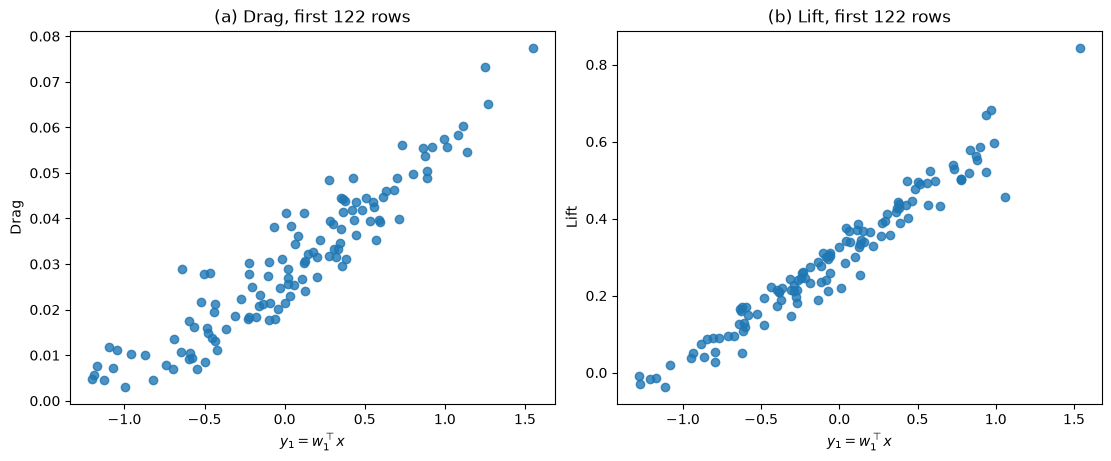

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), layout='constrained')
for j, q in enumerate(['Drag', 'Lift']):
    s = ac.orient(sub_book[q], by='covariance', X=X_all[:M_book], f=f_all[q][:M_book], columns=1)
    ac.plotting.plot_sufficient_summary(s, X=X_all[:M_book], f=f_all[q][:M_book], dims=1, ax=axes[j])
    axes[j].set_title(f'({"ab"[j]}) {q}, first {M_book} rows')
    print(f'{q}: sign of w1 relative to the 2016 rule: {np.sign(s.W[0, 0]):+.0f}')

In [11]:
print(f'Total run time: {time.perf_counter() - t_start:.1f} s')

Total run time: 7.8 s
